In [9]:
import matplotlib.pyplot as plt
import os
import tensorflow as tf

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!wget -P "/content/drive/MyDrive/driving_dataset/" https://iitgoffice-my.sharepoint.com/:f:/g/personal/anirban_dasgupta_iitg_ac_in/IgD6FWMGjQhKRaATJ0ge9eKeAfWP1tobzwXMx1UTBIIEAio?e=T3hrCJ

--2026-05-21 15:26:33--  https://iitgoffice-my.sharepoint.com/:f:/g/personal/anirban_dasgupta_iitg_ac_in/IgD6FWMGjQhKRaATJ0ge9eKeAfWP1tobzwXMx1UTBIIEAio?e=T3hrCJ
Resolving iitgoffice-my.sharepoint.com (iitgoffice-my.sharepoint.com)... 13.107.136.10, 13.107.138.10, 2620:1ec:8f8::10, ...
Connecting to iitgoffice-my.sharepoint.com (iitgoffice-my.sharepoint.com)|13.107.136.10|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://iitgoffice-my.sharepoint.com/personal/anirban_dasgupta_iitg_ac_in/_layouts/15/onedrive.aspx?id=%2Fpersonal%2Fanirban%5Fdasgupta%5Fiitg%5Fac%5Fin%2FDocuments%2FMy%20Documents%2FDatasets%2FManual%20Distraction%2Fdataset%2Fstage2&ga=1 [following]
--2026-05-21 15:26:33--  https://iitgoffice-my.sharepoint.com/personal/anirban_dasgupta_iitg_ac_in/_layouts/15/onedrive.aspx?id=%2Fpersonal%2Fanirban%5Fdasgupta%5Fiitg%5Fac%5Fin%2FDocuments%2FMy%20Documents%2FDatasets%2FManual%20Distraction%2Fdataset%2Fstage2&ga=1
Reusing existing connection t

In [12]:
dataset_path = "/content/drive/MyDrive/driving_dataset/stage2"
os.listdir(dataset_path)

['train', 'val']

In [13]:
train_path = dataset_path + "/train"
val_path = dataset_path + "/val"

print("Train Classes:")
print(os.listdir(train_path))

print("\nValidation Classes:")
print(os.listdir(val_path))

Train Classes:
['phone_use', 'other', 'eating', 'drinking']

Validation Classes:
['phone_use', 'other', 'drinking', 'eating']


In [14]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 3434 files belonging to 4 classes.
Found 1329 files belonging to 4 classes.


In [15]:
class_names = train_dataset.class_names

print(class_names)

['drinking', 'eating', 'other', 'phone_use']


In [16]:
for images, labels in train_dataset.take(1):
    print(images.shape)
    print(labels.shape)

(32, 224, 224, 3)
(32,)


Some Images are rotated while some are not

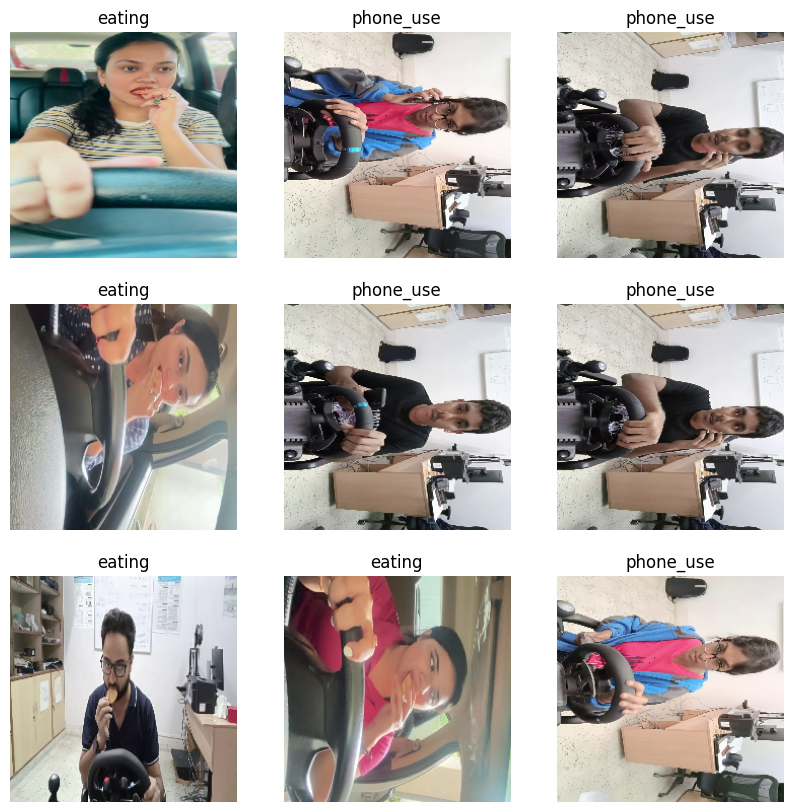

In [17]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

In [20]:
train_dataset = train_dataset.map(
    lambda x, y: (tf.image.rot90(x, k=3), y)
)

val_dataset = val_dataset.map(
    lambda x, y: (tf.image.rot90(x, k=3), y)
)

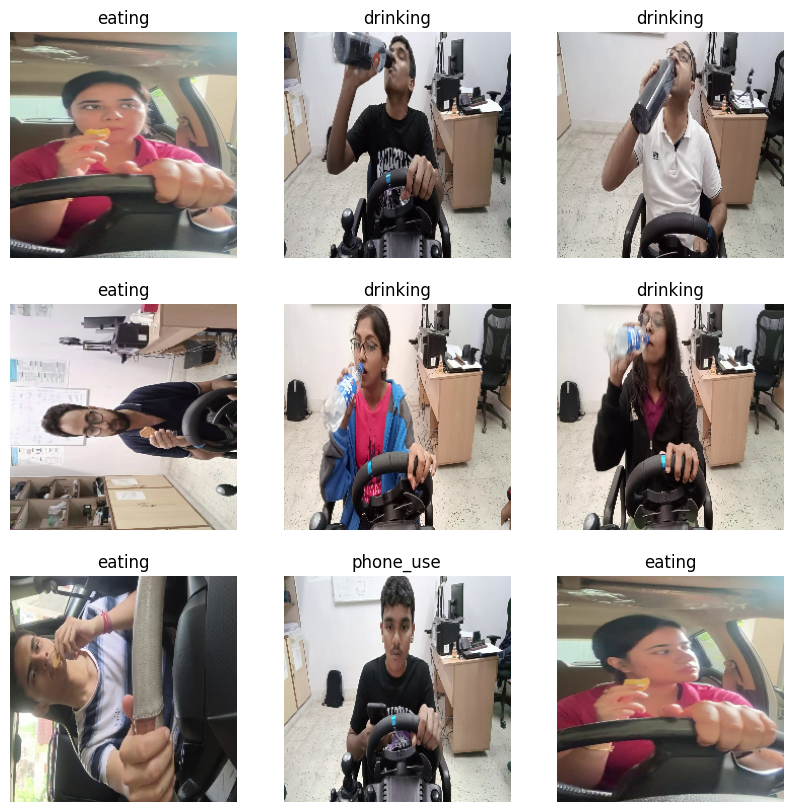

In [21]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

In [22]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

In [23]:
efficientnet_base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

In [24]:
efficientnet_base_model.trainable = False

In [25]:
efficientnet_model = models.Sequential([

    efficientnet_base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(4, activation='softmax')

])

In [26]:
efficientnet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [27]:
efficientnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/driving_dataset/stage2/best_efficientnet_stage2_model_v1.keras",
    save_best_only=True,
    monitor='val_accuracy'
)

earlystop = tf.keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True
)

In [29]:
efficientnet_model_history = efficientnet_model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=[checkpoint, earlystop]

)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 968s 9s/step - accuracy: 0.8844 - loss: 0.3593 - val_accuracy: 0.9917 - val_loss: 0.1050
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 50s 468ms/step - accuracy: 0.9840 - loss: 0.0956 - val_accuracy: 0.9977 - val_loss: 0.0508
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 81s 455ms/step - accuracy: 0.9913 - loss: 0.0598 - val_accuracy: 0.9985 - val_loss: 0.0315
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 83s 467ms/step - accuracy: 0.9942 - loss: 0.0430 - val_accuracy: 1.0000 - val_loss: 0.0225
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 487ms/step - accuracy: 0.9950 - loss: 0.0325 - val_accuracy: 1.0000 - val_loss: 0.0183
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 50s 459ms/step - accuracy: 0.9962 - loss: 0.0265 - val_accuracy: 1.0000 - val_loss: 0.0143
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 82s 463ms/step - accuracy: 0.9959 - loss: 0.0222 - val_accuracy: 1.0000 - val_loss: 0.0111
Epoch 8/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 50s 462ms/step - accuracy: 0.9977 - loss: 0.0

In [30]:
import json

with open("/content/drive/MyDrive/driving_dataset/stage2/history_efficientnet_stage2.json", "w") as f:

    json.dump(efficientnet_model_history.history, f)

In [32]:
acc = efficientnet_model_history.history['accuracy']
val_acc = efficientnet_model_history.history['val_accuracy']

loss = efficientnet_model_history.history['loss']
val_loss = efficientnet_model_history.history['val_loss']

epochs_range = range(len(acc))

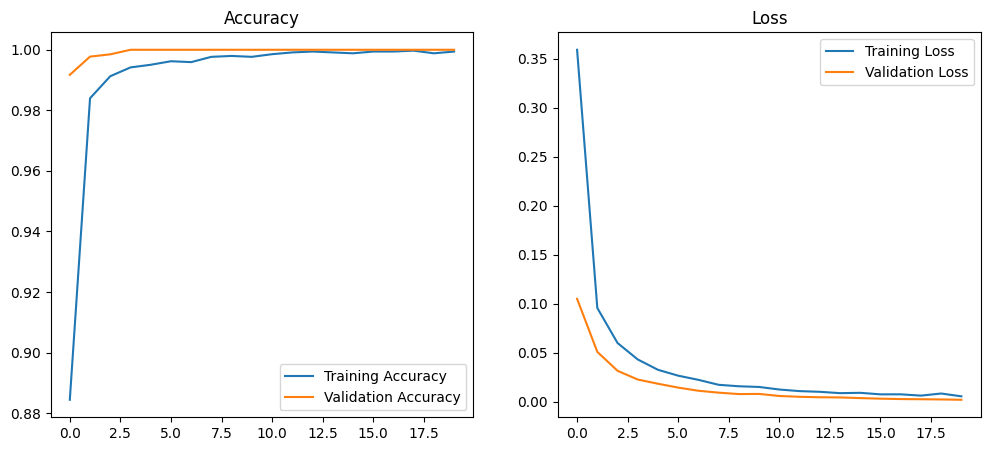

In [33]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

In [34]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/stage2/efficientnet_accuracy_loss_plot.png"
)

<Figure size 640x480 with 0 Axes>

In [35]:
y_true = []
y_pred = []

In [36]:
for images, labels in val_dataset:

    predictions = efficientnet_model.predict(images)

    predicted_labels = tf.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())

    y_pred.extend(predicted_labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

In [37]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [38]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[438   0   0   0]
 [  0 250   0   0]
 [  0   0  40   0]
 [  0   0   0 601]]


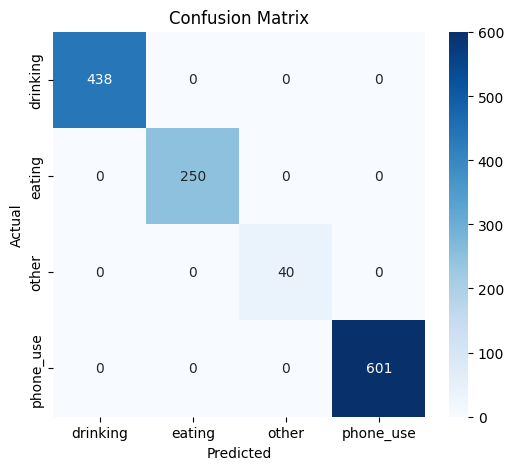

In [39]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [40]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/stage2/efficientnet_confusion_matrix.png"
)

<Figure size 640x480 with 0 Axes>

In [41]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

    drinking       1.00      1.00      1.00       438
      eating       1.00      1.00      1.00       250
       other       1.00      1.00      1.00        40
   phone_use       1.00      1.00      1.00       601

    accuracy                           1.00      1329
   macro avg       1.00      1.00      1.00      1329
weighted avg       1.00      1.00      1.00      1329



# ResNet50 Model


In [42]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

In [43]:
resnet_base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [44]:
resnet_base_model.trainable = False

In [45]:
resnet_model = models.Sequential([

    resnet_base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(4, activation='softmax')

])

In [46]:
resnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [47]:
resnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [48]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/driving_dataset/stage2/best_resnet50_stage2.keras",
    save_best_only=True,
    monitor='val_accuracy'
)

earlystop = tf.keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True
)

In [49]:
resnet_history = resnet_model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    callbacks=[checkpoint, earlystop]

)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 86s 580ms/step - accuracy: 0.8896 - loss: 0.2780 - val_accuracy: 0.9932 - val_loss: 0.0662
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 56s 514ms/step - accuracy: 0.9744 - loss: 0.0828 - val_accuracy: 0.9940 - val_loss: 0.0387
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 52s 475ms/step - accuracy: 0.9907 - loss: 0.0391 - val_accuracy: 0.9977 - val_loss: 0.0194
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 57s 518ms/step - accuracy: 0.9965 - loss: 0.0243 - val_accuracy: 0.9962 - val_loss: 0.0149
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 51s 471ms/step - accuracy: 0.9945 - loss: 0.0230 - val_accuracy: 0.9992 - val_loss: 0.0091
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 58s 532ms/step - accuracy: 0.9974 - loss: 0.0162 - val_accuracy: 1.0000 - val_loss: 0.0115
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 57s 524ms/step - accuracy: 0.9971 - loss: 0.0150 - val_accuracy: 1.0000 - val_loss: 0.0057
Epoch 8/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 79s 499ms/step - accuracy: 0.9977 - loss: 0

In [50]:
import json

with open("/content/drive/MyDrive/driving_dataset/stage2/history_resnet50_stage2.json", "w") as f:

    json.dump(resnet_history.history, f)

In [51]:
resnet_model.save(
    "/content/drive/MyDrive/driving_dataset/stage2/best_resnet50_stage2.keras"
)

In [52]:
acc = resnet_history.history['accuracy']
val_acc = resnet_history.history['val_accuracy']

loss = resnet_history.history['loss']
val_loss = resnet_history.history['val_loss']

epochs_range = range(len(acc))

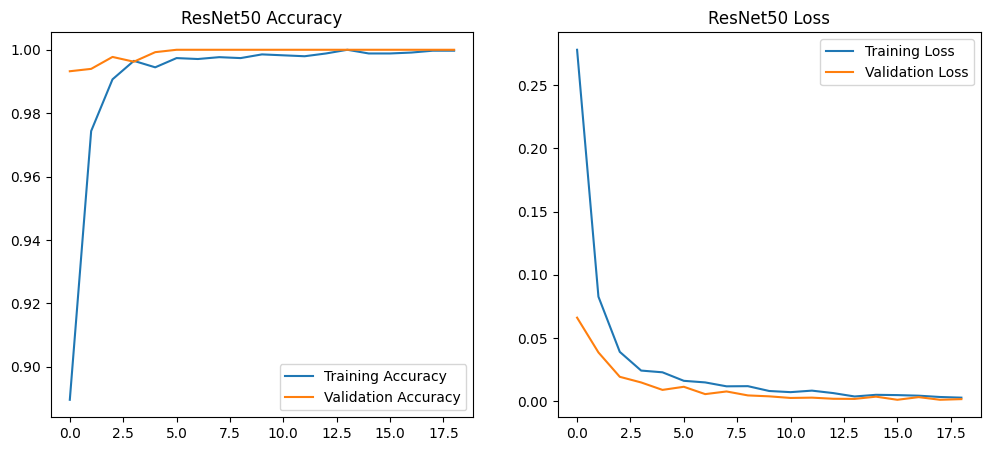

In [53]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('ResNet50 Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('ResNet50 Loss')

plt.show()

In [54]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/stage2/resnet50_accuracy_loss_plot.png"
)

<Figure size 640x480 with 0 Axes>

In [55]:
y_true_res = []
y_pred_res = []

for images, labels in val_dataset:

    predictions = resnet_model.predict(images)

    predicted_labels = tf.argmax(predictions, axis=1)

    y_true_res.extend(labels.numpy())

    y_pred_res.extend(predicted_labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 683ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

In [56]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [57]:
cm = confusion_matrix(y_true_res, y_pred_res)

print(cm)

[[438   0   0   0]
 [  0 250   0   0]
 [  0   0  40   0]
 [  0   0   0 601]]


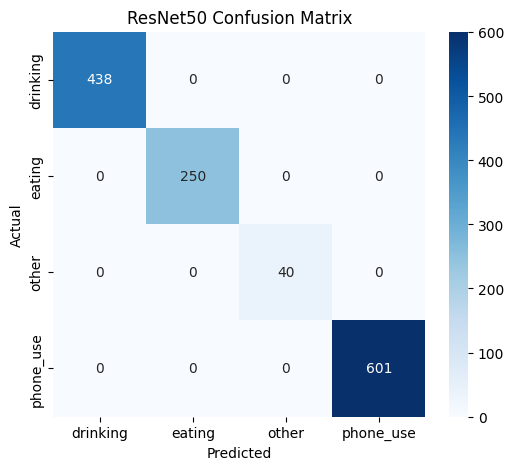

In [58]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix")

plt.show()

In [59]:
plt.savefig(
    "/content/drive/MyDrive/driving_dataset/stage2/resnet50_confusion_matrix.png"
)

<Figure size 640x480 with 0 Axes>

In [60]:
print(classification_report(
    y_true_res,
    y_pred_res,
    target_names=class_names
))

              precision    recall  f1-score   support

    drinking       1.00      1.00      1.00       438
      eating       1.00      1.00      1.00       250
       other       1.00      1.00      1.00        40
   phone_use       1.00      1.00      1.00       601

    accuracy                           1.00      1329
   macro avg       1.00      1.00      1.00      1329
weighted avg       1.00      1.00      1.00      1329

